# Трансформер за корекцију граматике

Енкодер-декодер трансформер модел обучен да исправља граматички неисправне реченице на енглеском језику.

**Скуп података:** [Grammar Correction](https://www.kaggle.com/datasets/satishgunjal/grammar-correction) од Satish Gunjal

## 1. Увоз библиотека

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset as TorchDataset, DataLoader, random_split, Subset
from torch.utils.tensorboard import SummaryWriter

import math
import warnings
import random
import difflib
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm

from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Whitespace
from datasets import Dataset as HFDataset
from torchmetrics.text import BLEUScore
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

2026-03-04 09:47:57.468061: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772617677.836517      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772617677.938401      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772617678.888603      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772617678.888668      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772617678.888673      24 computation_placer.cc:177] computation placer alr

## 2. Конфигурација

In [2]:
config = {
    "batch_size": 32,
    "num_epochs": 300,
    "learning_rate": 1e-3,
    "context_size": 128,
    "model_dimension": 256,
    "number_of_blocks": 3,
    "heads": 8,
    "dropout": 0.25,
    "feed_forward_dimension": 1024,
    "model_folder": "weights",
    "model_basename": "grammar_correction_",
    "preload": None,
    "tokenizer_file": "tokenizer.json",
    "experiment_name": "runs/grammar_correction",
    "dataset_path": "/kaggle/input/grammar-correction/Grammar Correction.csv",
    "seed": 42,
    "warmup_steps": 4000,
    "curriculum_phase_epochs": 30,
    "curriculum_phases": 4, # Svi podaci idu nakon (phases * phase_epochs)
}

def get_weights_file_path(epoch: str) -> str:
    model_filename = f"{config['model_basename']}{epoch}.pt"
    return str(Path('.') / config['model_folder'] / model_filename)


def get_latest_weights() -> str:
    model_filenames = list(Path(config['model_folder']).glob(f"{config['model_basename']}*"))
    if len(model_filenames) == 0:
        return None
    
    model_filenames.sort(key=lambda f: int(f.stem.split('_')[-1]))
    return str(model_filenames[-1])

torch.manual_seed(config["seed"])
random.seed(config["seed"])

## 3. Архитектура модела

Комплетна имплементација енкодер-декодер трансформера по узору на рад "Attention Is All You Need" и доступне материјале са предмета.

In [3]:
class InputEmbeddings(nn.Module):
    def __init__(self, model_dimension: int, vocab_size: int) -> None:
        super().__init__()
        self.model_dimension = model_dimension
        self.vocab_size = vocab_size
        self.embedding = nn.Embedding(vocab_size, model_dimension)

    def forward(self, x) -> torch.Tensor:
        return self.embedding(x) * math.sqrt(self.model_dimension)


class PositionalEncoding(nn.Module):
    def __init__(self, model_dimension: int, context_size: int, dropout: float) -> None:
        super().__init__()
        self.model_dimension = model_dimension
        self.context_size = context_size
        self.dropout = nn.Dropout(dropout)

        positional_encodings = torch.zeros(context_size, model_dimension)
        position = torch.arange(0, context_size, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, model_dimension, 2).float() * (-math.log(10000.0) / model_dimension))
        positional_encodings[:, 0::2] = torch.sin(position * div_term)
        positional_encodings[:, 1::2] = torch.cos(position * div_term)
        positional_encodings = positional_encodings.unsqueeze(0)
        self.register_buffer('pe', positional_encodings)

    def forward(self, x):
        x += (self.pe[:, :x.shape[1], :]).requires_grad_(False)
        return self.dropout(x)


class LayerNormalization(nn.Module):
    def __init__(self, features: int) -> None:
        super().__init__()
        self.eps = 1e-6
        self.alpha = nn.Parameter(torch.ones(features))
        self.bias = nn.Parameter(torch.zeros(features))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        std = x.std(dim=-1, keepdim=True)
        return self.alpha * (x - mean) / (std + self.eps) + self.bias


class MultiHeadAttentionBlock(nn.Module):
    def __init__(self, model_dimension: int, heads: int, dropout: float) -> None:
        super().__init__()
        self.model_dimension = model_dimension
        self.heads = heads
        self.dropout = nn.Dropout(dropout)
        assert model_dimension % heads == 0
        self.head_dimension = model_dimension // heads
        self.w_q = nn.Linear(model_dimension, model_dimension)
        self.w_k = nn.Linear(model_dimension, model_dimension)
        self.w_v = nn.Linear(model_dimension, model_dimension)
        self.w_o = nn.Linear(model_dimension, model_dimension)

    @staticmethod
    def attention(query, key, value, mask, dropout: nn.Dropout):
        head_dimension = query.shape[-1]
        attention_scores = (query @ key.transpose(-2, -1)) / math.sqrt(head_dimension)
        if mask is not None:
            attention_scores.masked_fill_(mask == 0, -1e9)
        attention_scores = attention_scores.softmax(dim=-1)
        if dropout is not None:
            attention_scores = dropout(attention_scores)
        return (attention_scores @ value), attention_scores

    def forward(self, q, k, v, mask):
        query = self.w_q(q)
        key = self.w_k(k)
        value = self.w_v(v)
        query = query.view(query.shape[0], query.shape[1], self.heads, self.head_dimension).transpose(1, 2)
        key = key.view(key.shape[0], key.shape[1], self.heads, self.head_dimension).transpose(1, 2)
        value = value.view(value.shape[0], value.shape[1], self.heads, self.head_dimension).transpose(1, 2)
        x, self.attention_scores = MultiHeadAttentionBlock.attention(query, key, value, mask, self.dropout)
        x = x.transpose(1, 2).contiguous().view(x.shape[0], -1, self.heads * self.head_dimension)
        return self.w_o(x)


class FeedForwardBlock(nn.Module):
    def __init__(self, model_dimension: int, feed_forward_dimension: int, dropout: float) -> None:
        super().__init__()
        self.linear_1 = nn.Linear(model_dimension, feed_forward_dimension)
        self.dropout = nn.Dropout(dropout)
        self.linear_2 = nn.Linear(feed_forward_dimension, model_dimension)

    def forward(self, x):
        return self.linear_2(self.dropout(torch.relu(self.linear_1(x))))

class ResidualConnection(nn.Module):
    def __init__(self, features: int, dropout: float) -> None:
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.norm = LayerNormalization(features)

    def forward(self, x, sublayer):
        return x + self.dropout(sublayer(self.norm(x)))

class ProjectionLayer(nn.Module):
    def __init__(self, model_dimension: int, vocab_size: int) -> None:
        super().__init__()
        self.proj = nn.Linear(model_dimension, vocab_size)

    def forward(self, x):
        return self.proj(x)

In [4]:
class EncoderBlock(nn.Module):
    def __init__(self, features: int, self_attention_block: MultiHeadAttentionBlock, feed_forward_block: FeedForwardBlock, dropout: float) -> None:
        super().__init__()
        self.self_attention_block = self_attention_block
        self.feed_forward_block = feed_forward_block
        self.residual_connections = nn.ModuleList([ResidualConnection(features, dropout) for _ in range(2)])

    def forward(self, x, source_mask):
        x = self.residual_connections[0](x, lambda x: self.self_attention_block(x, x, x, source_mask))
        x = self.residual_connections[1](x, self.feed_forward_block)
        return x

class Encoder(nn.Module):
    def __init__(self, features: int, layers: nn.ModuleList) -> None:
        super().__init__()
        self.layers = layers
        self.norm = LayerNormalization(features)

    def forward(self, x, mask):
        for layer in self.layers:
            x = layer(x, mask)
        return self.norm(x)

class DecoderBlock(nn.Module):
    def __init__(self, features: int, self_attention_block: MultiHeadAttentionBlock, cross_attention_block: MultiHeadAttentionBlock, feed_forward_block: FeedForwardBlock, dropout: float) -> None:
        super().__init__()
        self.self_attention_block = self_attention_block
        self.cross_attention_block = cross_attention_block
        self.feed_forward_block = feed_forward_block
        self.residual_connections = nn.ModuleList([ResidualConnection(features, dropout) for _ in range(3)])

    def forward(self, x, encoder_output, source_mask, target_mask):
        x = self.residual_connections[0](x, lambda x: self.self_attention_block(x, x, x, target_mask))
        x = self.residual_connections[1](x, lambda x: self.cross_attention_block(x, encoder_output, encoder_output, source_mask))
        x = self.residual_connections[2](x, self.feed_forward_block)
        return x


class Decoder(nn.Module):
    def __init__(self, features: int, layers: nn.ModuleList) -> None:
        super().__init__()
        self.layers = layers
        self.norm = LayerNormalization(features)

    def forward(self, x, encoder_output, source_mask, target_mask):
        for layer in self.layers:
            x = layer(x, encoder_output, source_mask, target_mask)
        return self.norm(x)


class Transformer(nn.Module):
    def __init__(self, encoder: Encoder, decoder: Decoder, source_embed: InputEmbeddings, target_embed: InputEmbeddings, source_pos: PositionalEncoding, target_pos: PositionalEncoding, projection_layer: ProjectionLayer) -> None:
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.source_embed = source_embed
        self.target_embed = target_embed
        self.source_pos = source_pos
        self.target_pos = target_pos
        self.projection_layer = projection_layer

    def encode(self, source, source_mask):
        source = self.source_embed(source)
        source = self.source_pos(source)
        return self.encoder(source, source_mask)

    def decode(self, encoder_output, source_mask, target, target_mask):
        target = self.target_embed(target)
        target = self.target_pos(target)
        return self.decoder(target, encoder_output, source_mask, target_mask)

    def project(self, x):
        return self.projection_layer(x)

In [5]:
def get_model(source_vocab_size: int, target_vocab_size: int) -> Transformer:
    model_dimension = config['model_dimension']
    heads = config['heads']
    dropout = config['dropout']
    feed_forward_dimension = config['feed_forward_dimension']
    number_of_blocks = config['number_of_blocks']
    context_size = config['context_size']

    source_embed = InputEmbeddings(model_dimension, source_vocab_size)
    target_embed = InputEmbeddings(model_dimension, target_vocab_size)

    source_pos = PositionalEncoding(model_dimension, context_size, dropout)
    target_pos = PositionalEncoding(model_dimension, context_size, dropout)

    encoder_blocks = []
    for _ in range(number_of_blocks):
        encoder_self_attention_block = MultiHeadAttentionBlock(model_dimension, heads, dropout)
        feed_forward_block = FeedForwardBlock(model_dimension, feed_forward_dimension, dropout)
        encoder_block = EncoderBlock(model_dimension, encoder_self_attention_block, feed_forward_block, dropout)
        encoder_blocks.append(encoder_block)

    decoder_blocks = []
    for _ in range(number_of_blocks):
        decoder_self_attention_block = MultiHeadAttentionBlock(model_dimension, heads, dropout)
        decoder_cross_attention_block = MultiHeadAttentionBlock(model_dimension, heads, dropout)
        feed_forward_block = FeedForwardBlock(model_dimension, feed_forward_dimension, dropout)
        decoder_block = DecoderBlock(model_dimension, decoder_self_attention_block, decoder_cross_attention_block, feed_forward_block, dropout)
        decoder_blocks.append(decoder_block)

    encoder = Encoder(model_dimension, nn.ModuleList(encoder_blocks))
    decoder = Decoder(model_dimension, nn.ModuleList(decoder_blocks))
    projection_layer = ProjectionLayer(model_dimension, target_vocab_size)

    transformer = Transformer(encoder, decoder, source_embed, target_embed, source_pos, target_pos, projection_layer)

    for p in transformer.parameters():
        if p.dim() > 1:
            nn.init.xavier_uniform_(p)

    return transformer

## 4. Скуп података

In [6]:
class BilingualDataset(TorchDataset):
    def __init__(self, dataset, tokenizer):
        super().__init__()
        self.context_size = config['context_size']
        self.dataset = dataset
        self.tokenizer = tokenizer
        self.sos_token = torch.tensor([tokenizer.token_to_id('[SOS]')], dtype=torch.int64)
        self.eos_token = torch.tensor([tokenizer.token_to_id('[EOS]')], dtype=torch.int64)
        self.pad_token = torch.tensor([tokenizer.token_to_id('[PAD]')], dtype=torch.int64)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        source_target_pair = self.dataset[index]
        source_text = source_target_pair['translation']['source']
        target_text = source_target_pair['translation']['target']

        encoder_input_tokens = self.tokenizer.encode(source_text).ids
        decoder_input_tokens = self.tokenizer.encode(target_text).ids

        encoder_num_padding_tokens = self.context_size - len(encoder_input_tokens) - 2
        decoder_num_padding_tokens = self.context_size - len(decoder_input_tokens) - 1

        if encoder_num_padding_tokens < 0 or decoder_num_padding_tokens < 0:
            raise ValueError("Recenica je predugacka!")

        encoder_input = torch.cat([
            self.sos_token,
            torch.tensor(encoder_input_tokens, dtype=torch.int64),
            self.eos_token,
            torch.tensor([self.pad_token] * encoder_num_padding_tokens, dtype=torch.int64)
        ], dim=0)

        decoder_input = torch.cat([
            self.sos_token,
            torch.tensor(decoder_input_tokens, dtype=torch.int64),
            torch.tensor([self.pad_token] * decoder_num_padding_tokens, dtype=torch.int64)
        ], dim=0)

        label = torch.cat([
            torch.tensor(decoder_input_tokens, dtype=torch.int64),
            self.eos_token,
            torch.tensor([self.pad_token] * decoder_num_padding_tokens, dtype=torch.int64)
        ], dim=0)

        assert encoder_input.size(0) == self.context_size
        assert decoder_input.size(0) == self.context_size
        assert label.size(0) == self.context_size

        return {
            "encoder_input": encoder_input,
            "decoder_input": decoder_input,
            "encoder_mask": (encoder_input != self.pad_token).unsqueeze(0).unsqueeze(0).int(),
            "decoder_mask": (decoder_input != self.pad_token).unsqueeze(0).int() & causal_mask(decoder_input.size(0)),
            "label": label,
            "source_text": source_text,
            "target_text": target_text
        }


def causal_mask(size: int) -> torch.Tensor:
    mask = torch.triu(torch.ones(1, size, size), diagonal=1).type(torch.int)
    return mask == 0


def compute_difficulty(source: str, target: str) -> int:
    source_words = source.split()
    target_words = target.split()
    matcher = difflib.SequenceMatcher(None, source_words, target_words)
    edits = 0
    for op, i1, i2, j1, j2 in matcher.get_opcodes():
        if op != 'equal':
            edits += max(i2 - i1, j2 - j1)
    return edits


def load_data():
    df = pd.read_csv(config['dataset_path'])
    
    data = {'id': [], 'translation': [], 'difficulty': []}
    for i, row in df.iterrows():
        ungrammatical = str(row['Ungrammatical Statement']).strip().lower()
        corrected = str(row['Standard English']).strip().lower()

        if not ungrammatical or not corrected or ungrammatical == 'nan' or corrected == 'nan':
            continue

        difficulty = compute_difficulty(ungrammatical, corrected)

        # Originalni set
        data['id'].append(str(i))
        data['translation'].append({
            'source': ungrammatical,
            'target': corrected
        })
        data['difficulty'].append(difficulty)

        # 1. augmentacija (ispravne recenice, bez gresaka)
        data['id'].append(f"{i}_identity")
        data['translation'].append({
            'source': corrected,
            'target': corrected
        })
        data['difficulty'].append(0)

        # 2. augmentacija (nedostatak clanova)
        articles = {'a', 'an', 'the'}
        words = corrected.split()
        words_no_articles = [w for w in words if w not in articles]
        if len(words_no_articles) < len(words):
            no_article_sentence = ' '.join(words_no_articles)
            data['id'].append(f"{i}_no_article")
            data['translation'].append({
                'source': no_article_sentence,
                'target': corrected
            })
            data['difficulty'].append(compute_difficulty(no_article_sentence, corrected))

        # 3. augmentacija: zamjena uzastopnih rijeci
        if len(words) >= 2:
            swap_idx = random.randint(0, len(words) - 2)
            swapped_words = words.copy()
            swapped_words[swap_idx], swapped_words[swap_idx + 1] = swapped_words[swap_idx + 1], swapped_words[swap_idx]
            swapped_sentence = ' '.join(swapped_words)
            if swapped_sentence != corrected:
                data['id'].append(f"{i}_swap")
                data['translation'].append({
                    'source': swapped_sentence,
                    'target': corrected
                })
                data['difficulty'].append(compute_difficulty(swapped_sentence, corrected))

    dataset = HFDataset.from_dict(data)

    difficulties = data['difficulty']
    identity_count = sum(1 for d in difficulties if d == 0)
    easy_count = sum(1 for d in difficulties if d <= 2)
    hard_count = sum(1 for d in difficulties if d > 2)
    print(f"Statistika po kompleksnosti: identitet (0 izmjena): {identity_count}, lako (<=2 izmjene): {easy_count}, tesko (>2 izmjene): {hard_count}, ukupno: {len(difficulties)}")

    return dataset

## 5. Инференца и валидација

In [7]:
def greedy_decode(model, source, source_mask, tokenizer, max_len, device):
    sos_idx = tokenizer.token_to_id('[SOS]')
    eos_idx = tokenizer.token_to_id('[EOS]')

    encoder_output = model.encode(source, source_mask)
    decoder_input = torch.empty(1, 1).fill_(sos_idx).type_as(source).to(device)

    while True:
        if decoder_input.size(1) == max_len:
            break
        decoder_mask = causal_mask(decoder_input.size(1)).type_as(source_mask).to(device)
        out = model.decode(encoder_output, source_mask, decoder_input, decoder_mask)
        prob = model.project(out[:, -1])
        _, next_word = torch.max(prob, dim=1)
        decoder_input = torch.cat(
            [decoder_input, torch.empty(1, 1).type_as(source).fill_(next_word.item()).to(device)],
            dim=1
        )
        if next_word == eos_idx:
            break

    return decoder_input.squeeze(0)


def beam_search_decode(model, source, source_mask, tokenizer, max_len, device, beam_size=3):
    sos_idx = tokenizer.token_to_id('[SOS]')
    eos_idx = tokenizer.token_to_id('[EOS]')

    encoder_output = model.encode(source, source_mask)

    beams = [(0.0, torch.empty(1, 1).fill_(sos_idx).type_as(source).to(device))]
    completed = []

    for _ in range(max_len):
        new_beams = []
        for score, seq in beams:
            if seq[0, -1].item() == eos_idx:
                completed.append((score, seq))
                continue

            decoder_mask = causal_mask(seq.size(1)).type_as(source_mask).to(device)
            out = model.decode(encoder_output, source_mask, seq, decoder_mask)
            logits = model.project(out[:, -1])
            log_probs = torch.log_softmax(logits, dim=-1)

            topk_log_probs, topk_indices = torch.topk(log_probs, beam_size, dim=1)

            for k in range(beam_size):
                token = topk_indices[0, k].item()
                new_score = score + topk_log_probs[0, k].item()
                new_seq = torch.cat([seq, torch.empty(1, 1).type_as(source).fill_(token).to(device)], dim=1)
                new_beams.append((new_score, new_seq))

        if not new_beams:
            break

        new_beams.sort(key=lambda x: x[0], reverse=True)
        beams = new_beams[:beam_size]

    completed.extend(beams)

    best_score, best_seq = max(completed, key=lambda x: x[0] / x[1].size(1))
    return best_seq.squeeze(0)


def run_validation_visualization(model, validation_dataloader, tokenizer, max_len, device, print_msg, number_examples=2):
    model.eval()
    count = 0

    with torch.no_grad():
        for batch in validation_dataloader:
            count += 1
            if count > number_examples:
                break

            encoder_input = batch['encoder_input'].to(device)
            encoder_mask = batch['encoder_mask'].to(device)

            model_out = greedy_decode(model, encoder_input[0:1], encoder_mask[0:1], tokenizer, max_len, device)

            source_text = batch['source_text'][0]
            target_text = batch['target_text'][0]
            model_out_text = tokenizer.decode(model_out.detach().cpu().numpy())

            print_msg('-' * 50)
            print_msg(f'input: {source_text}')
            print_msg(f'expected: {target_text}')
            print_msg(f'actual: {model_out_text}')


def run_validation(model, validation_dataloader, loss_function, tokenizer, device, max_len=128, num_bleu_examples=50):
    model.eval()
    total_loss = 0
    num_batches = 0

    bleu_metric = BLEUScore(n_gram=4)
    predictions = []
    references = []
    bleu_count = 0

    with torch.no_grad():
        for batch in validation_dataloader:
            encoder_input = batch['encoder_input'].to(device)
            decoder_input = batch['decoder_input'].to(device)
            encoder_mask = batch['encoder_mask'].to(device)
            decoder_mask = batch['decoder_mask'].to(device)
            label = batch['label'].to(device)

            encoder_output = model.encode(encoder_input, encoder_mask)
            decoder_output = model.decode(encoder_output, encoder_mask, decoder_input, decoder_mask)
            transformer_output = model.project(decoder_output)

            loss = loss_function(transformer_output.view(-1, tokenizer.get_vocab_size()), label.view(-1))
            total_loss += loss.item()
            num_batches += 1

            if bleu_count < num_bleu_examples:
                model_out = greedy_decode(model, encoder_input[0:1], encoder_mask[0:1], tokenizer, max_len, device)
                pred_text = tokenizer.decode(model_out.detach().cpu().numpy())
                target_text = batch['target_text'][0]
                predictions.append(pred_text)
                references.append([target_text])
                bleu_count += 1

    avg_loss = total_loss / max(num_batches, 1)
    bleu_score = bleu_metric(predictions, references).item() if predictions else 0.0
    print(f"Gubitak na validaciji: {avg_loss:.4f} | BLEU skor: {bleu_score:.4f}")
    return avg_loss, bleu_score


def translate_sentence(sentence, model=None, tokenizer=None, max_len=None, device=None, use_beam_search=False, beam_size=3):
    if device is None:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    if tokenizer is None:
        tokenizer = Tokenizer.from_file(config['tokenizer_file'])

    if max_len is None:
        max_len = config['context_size']

    if model is None:
        vocab_size = tokenizer.get_vocab_size()
        model = get_model(vocab_size, vocab_size).to(device)
        model_filename = get_latest_weights()
        if model_filename is None:
            return "<model nije pronadjen>"
        state = torch.load(model_filename, map_location=device)
        model.load_state_dict(state['model_state_dict'])

    model.eval()

    sos_idx = tokenizer.token_to_id('[SOS]')
    eos_idx = tokenizer.token_to_id('[EOS]')
    pad_idx = tokenizer.token_to_id('[PAD]')

    source_tokens = tokenizer.encode(sentence.lower()).ids

    encoder_num_padding = max_len - len(source_tokens) - 2
    if encoder_num_padding < 0:
        source_tokens = source_tokens[:max_len - 2]
        encoder_num_padding = 0

    encoder_input = torch.cat([
        torch.tensor([sos_idx], dtype=torch.int64),
        torch.tensor(source_tokens, dtype=torch.int64),
        torch.tensor([eos_idx], dtype=torch.int64),
        torch.tensor([pad_idx] * encoder_num_padding, dtype=torch.int64)
    ], dim=0).unsqueeze(0).to(device)

    encoder_mask = (encoder_input != pad_idx).unsqueeze(1).unsqueeze(1).int().to(device)

    with torch.no_grad():
        if use_beam_search:
            output_tokens = beam_search_decode(model, encoder_input, encoder_mask, tokenizer, max_len, device, beam_size)
        else:
            output_tokens = greedy_decode(model, encoder_input, encoder_mask, tokenizer, max_len, device)

    return tokenizer.decode(output_tokens.detach().cpu().numpy())

## 6. Тренирање

In [8]:
def get_all_sentences_both(dataset):
    for item in dataset:
        yield item['translation']['source']
        yield item['translation']['target']


def build_tokenizer(sentences):
    tokenizer = Tokenizer(BPE(unk_token='[UNK]'))
    tokenizer.pre_tokenizer = Whitespace()
    trainer = BpeTrainer(
        special_tokens=["[UNK]", "[PAD]", "[SOS]", "[EOS]"],
        min_frequency=2,
        vocab_size=5000
    )
    tokenizer.train_from_iterator(sentences, trainer=trainer)

    tokenizer.save(config['tokenizer_file'])
    print(f"Broj tokena: {tokenizer.get_vocab_size()}.")
    return tokenizer


def get_dataset():
    dataset_raw = load_data()

    dataset_size = len(dataset_raw)
    train_size = int(0.9 * dataset_size)
    val_size = int(0.08 * dataset_size)
    test_size = dataset_size - train_size - val_size

    train_raw, val_raw, test_raw = random_split(dataset_raw, [train_size, val_size, test_size])

    sentences = list(get_all_sentences_both(train_raw))
    tokenizer = build_tokenizer(sentences)

    training_dataset = BilingualDataset(train_raw, tokenizer)

    curriculum_dataloaders = []
    print("Curriculum learning faze:")
    for phase in range(config['curriculum_phases']):
        indices = [i for i in range(len(train_raw)) if train_raw[i]['difficulty'] <= phase]
        subset = Subset(training_dataset, indices)
        dataloader = DataLoader(subset, batch_size=config['batch_size'], shuffle=True)
        curriculum_dataloaders.append(dataloader)
        start_epoch = phase * config['curriculum_phase_epochs']
        end_epoch = (phase + 1) * config['curriculum_phase_epochs'] - 1
        print(f"  Faza {phase + 1} (≤{phase} izmjena): {len(indices)} primjera, epohe {start_epoch}–{end_epoch}")

    full_dataloader = DataLoader(training_dataset, batch_size=config['batch_size'], shuffle=True)
    full_start = config['curriculum_phases'] * config['curriculum_phase_epochs']
    print(f"  Finalna faza: {len(training_dataset)} primjera, epohe {full_start}–{config['num_epochs'] - 1}")

    val_dataset = BilingualDataset(val_raw, tokenizer)
    test_dataset = BilingualDataset(test_raw, tokenizer)

    val_dataloader = DataLoader(val_dataset, batch_size=config['batch_size'], shuffle=True)
    test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=True)

    return curriculum_dataloaders, full_dataloader, val_dataloader, test_dataloader, tokenizer

In [9]:
def train_model():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    
    Path(config['model_folder']).mkdir(parents=True, exist_ok=True)

    curriculum_dataloaders, full_dataloader, val_dataloader, test_dataloader, tokenizer = get_dataset()
    vocab_size = tokenizer.get_vocab_size()
    model = get_model(vocab_size, vocab_size).to(device)

    writer = SummaryWriter(config['experiment_name'])
    optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'], eps=1e-9)

    all_dataloaders = curriculum_dataloaders + [full_dataloader]
    estimated_batches_per_epoch = max(len(dl) for dl in all_dataloaders)
    total_steps = estimated_batches_per_epoch * config['num_epochs']
    total_curriculum_epochs = config['curriculum_phases'] * config['curriculum_phase_epochs']

    def lr_lambda(step):
        step = max(step, 1)
        if step < config['warmup_steps']:
            return step / config['warmup_steps']
        progress = (step - config['warmup_steps']) / max(1, total_steps - config['warmup_steps'])
        return 0.5 * (1.0 + math.cos(math.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    initial_epoch = 0
    global_step = 0
    model_filename = get_latest_weights() if config['preload'] == 'latest' else get_weights_file_path(config['preload']) if config['preload'] else None

    if model_filename:
        print(f"Ucitavanje prethodno sacuvanog modela: {model_filename}.")
        state = torch.load(model_filename)
        model.load_state_dict(state['model_state_dict'])
        optimizer.load_state_dict(state['optimizer_state_dict'])
        if 'scheduler_state_dict' in state:
            scheduler.load_state_dict(state['scheduler_state_dict'])
        initial_epoch = state['epoch'] + 1
        global_step = state['global_step']
    else:
        print("Novo treniranje modela")

    loss_function = nn.CrossEntropyLoss(ignore_index=tokenizer.token_to_id('[PAD]'), label_smoothing=0.1).to(device)

    for epoch in range(initial_epoch, config['num_epochs']):
        current_phase = epoch // config['curriculum_phase_epochs']

        if current_phase < config['curriculum_phases']:
            training_dataloader = curriculum_dataloaders[current_phase]
            phase_label = f"FAZA {current_phase + 1} (≤{current_phase} izmjena)"
        else:
            training_dataloader = full_dataloader
            phase_label = "PUNA FAZA"

        batch_iterator = tqdm(training_dataloader, desc=f"[{phase_label}] Obrada epohe {epoch:02d}")
        for batch in batch_iterator:
            model.train()

            encoder_input = batch['encoder_input'].to(device)
            decoder_input = batch['decoder_input'].to(device)
            encoder_mask = batch['encoder_mask'].to(device)
            decoder_mask = batch['decoder_mask'].to(device)

            encoder_output = model.encode(encoder_input, encoder_mask)
            decoder_output = model.decode(encoder_output, encoder_mask, decoder_input, decoder_mask)
            transformer_output = model.project(decoder_output)

            label = batch['label'].to(device)
            loss = loss_function(transformer_output.view(-1, vocab_size), label.view(-1))
            batch_iterator.set_postfix({"gubitak": f"{loss.item():6.3f}"})

            writer.add_scalar('train_loss', loss.item(), global_step)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
            global_step += 1

        if epoch < total_curriculum_epochs and (epoch + 1) % config['curriculum_phase_epochs'] == 0:
            finished_phase = epoch // config['curriculum_phase_epochs']
            print(f"\n{'='*60}")
            if finished_phase + 1 < config['curriculum_phases']:
                print(f"Zavrsena faza {finished_phase + 1} (≤{finished_phase} izmjena). Prelaz na fazu {finished_phase + 2} (≤{finished_phase + 1} izmjena)...")
            else:
                print(f"Zavrsena faza {finished_phase + 1} (≤{finished_phase} izmjena). Prelaz na finalnu FAZU (svi podaci)...")
            print(f"{'='*60}\n")

        run_validation_visualization(model, val_dataloader, tokenizer, config['context_size'], device, lambda msg: batch_iterator.write(msg), number_examples=1)
        val_loss, bleu_score = run_validation(model, val_dataloader, loss_function, tokenizer, device, max_len=config['context_size'])
        writer.add_scalar('val_loss', val_loss, global_step)
        writer.add_scalar('bleu_score', bleu_score, global_step)
        writer.flush()

        model_filename = get_weights_file_path(f'{epoch:02d}')
        is_phase_end = epoch < total_curriculum_epochs and (epoch + 1) % config['curriculum_phase_epochs'] == 0
        if epoch % 10 == 9 or epoch == 0 or is_phase_end or epoch == config['num_epochs'] - 1:
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'global_step': global_step
            }, model_filename)

    print(f"Velicina test skupa: {len(test_dataloader.dataset)} primjera.")
    run_validation_visualization(model, test_dataloader, tokenizer, config['context_size'], device, lambda msg: print(msg), number_examples=50)

## 7. Покретање тренирања

In [10]:
warnings.filterwarnings('ignore')
train_model()

Statistika po kompleksnosti: identitet (0 izmjena): 2126, lako (<=2 izmjene): 7004, tesko (>2 izmjene): 668, ukupno: 7672



Broj tokena: 5000.
Curriculum learning faze:
  Faza 1 (≤0 izmjena): 1936 primjera, epohe 0–29
  Faza 2 (≤1 izmjena): 3635 primjera, epohe 30–59
  Faza 3 (≤2 izmjena): 6305 primjera, epohe 60–89
  Faza 4 (≤3 izmjena): 6606 primjera, epohe 90–119
  Finalna faza: 6904 primjera, epohe 120–299
Novo treniranje modela


[FAZA 1 (≤0 izmjena)] Obrada epohe 00: 100%|██████████| 61/61 [00:05<00:00, 11.63it/s, gubitak=8.153]


--------------------------------------------------
input: she put the flowers in a vase on the table.
expected: she put the flowers in a vase on the table.
actual: . the the the the the the . . . . . the the the . the . . . . . . . . the . the . . . . . . . . . . . . . . . . . . . . . the
Gubitak na validaciji: 7.9742 | BLEU skor: 0.0000


[FAZA 1 (≤0 izmjena)] Obrada epohe 01: 100%|██████████| 61/61 [00:04<00:00, 15.20it/s, gubitak=7.629]


--------------------------------------------------
input: could you gimme a hand with this heavy box?
expected: could you give me a hand with this heavy box?
actual: the the the the
Gubitak na validaciji: 7.4788 | BLEU skor: 0.0000


...

--------------------------------------------------
input: 46. i can't believe how fast my daughter is growing up.
expected: 46. i can't believe how fast my daughter is growing up.
actual: 46 . i can ' t believe how fast my daughter is growing up .
Gubitak na validaciji: 1.3176 | BLEU skor: 0.4718


[PUNA FAZA] Obrada epohe 298: 100%|██████████| 216/216 [00:14<00:00, 15.42it/s, gubitak=1.197]


--------------------------------------------------
input: table needs to be set before dinner.
expected: the table needs to be set before dinner.
actual: the table needs to be set before dinner .
Gubitak na validaciji: 1.3106 | BLEU skor: 0.4940


[PUNA FAZA] Obrada epohe 299: 100%|██████████| 216/216 [00:14<00:00, 14.92it/s, gubitak=1.195]


--------------------------------------------------
input: she complimented him on his decent performance.
expected: she complimented him on his decent performance.
actual: she complimented him on his dec ent performance .
Gubitak na validaciji: 1.3159 | BLEU skor: 0.5046
Velicina test skupa: 155 primjera.
--------------------------------------------------
input: he was completely devastated.
expected: he was completely devastated.
actual: he was completely devast ated .
--------------------------------------------------
input: she had a difficult time making a decision.
expected: she had a difficult time making a decision.
actual: she had a difficult time making a decision .
--------------------------------------------------
input: bus stopped on corner.
expected: the bus stopped on the corner.
actual: the bus stopped on the corner .
--------------------------------------------------
input: she has not been studying for her test, so she is unprepared.
expected: she has not been studyin

## 8. Тестирање модела

In [11]:
test_sentence = "She go to the store yesterday and buyed some foods."

tokenizer = Tokenizer.from_file(config['tokenizer_file'])
vocab_size = tokenizer.get_vocab_size()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = get_model(vocab_size, vocab_size).to(device)
state = torch.load(get_latest_weights(), map_location=device)
model.load_state_dict(state['model_state_dict'])

print("Greedy dekodiranje:")
print(translate_sentence(test_sentence, model=model, tokenizer=tokenizer, device=device))

print("\nBeam search dekodiranje (beam_size=3):")
print(translate_sentence(test_sentence, model=model, tokenizer=tokenizer, device=device, use_beam_search=True, beam_size=3))

Greedy dekodiranje:
she goes to the store yesterday and buy some food .

Beam search dekodiranje (beam_size=3):
she goes to the store yesterday and buy some food .


## 9. Визуелизација резултата тренирања

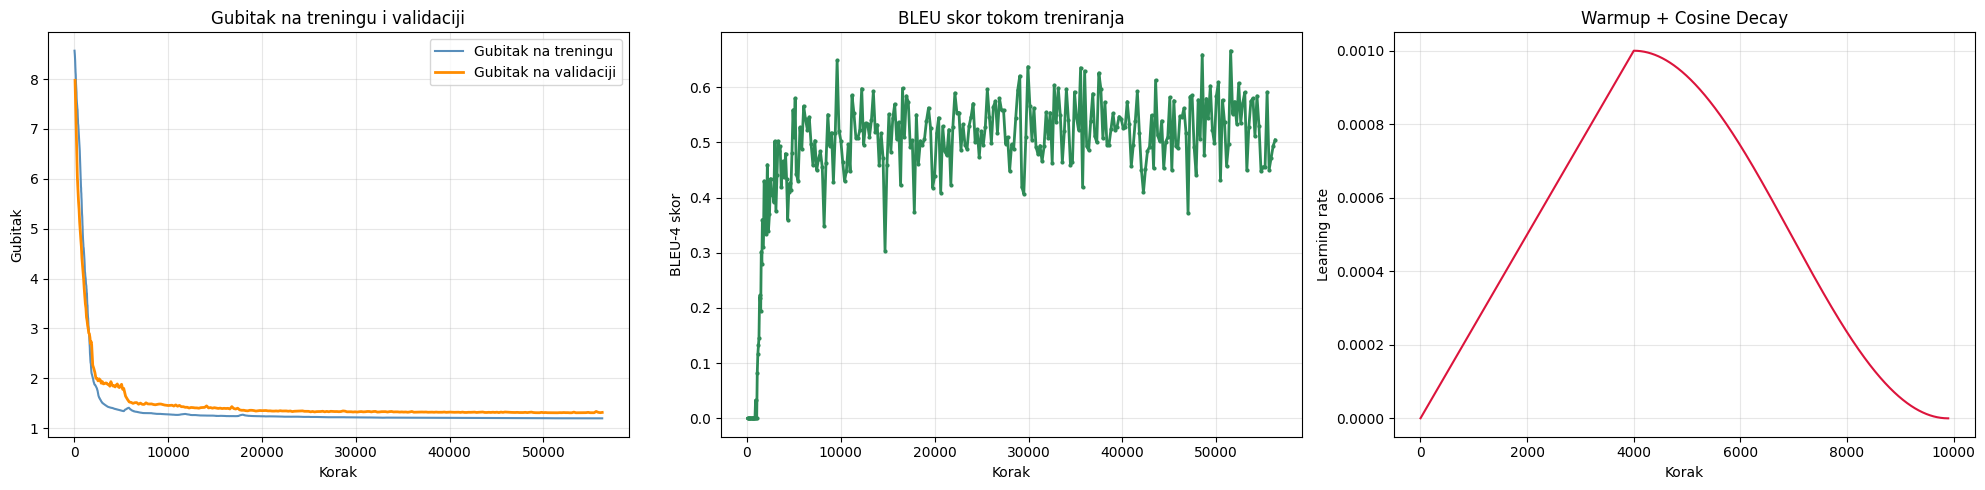


Konačni gubitak na validaciji: 1.3159
Konačni BLEU skor: 0.5046
Najbolji BLEU skor: 0.6662 (korak 51528)


In [12]:
ea = EventAccumulator(config['experiment_name'])
ea.Reload()

train_loss_events = ea.Scalars('train_loss')
val_loss_events = ea.Scalars('val_loss')
bleu_events = ea.Scalars('bleu_score')

train_steps = [e.step for e in train_loss_events]
train_loss = [e.value for e in train_loss_events]

val_steps = [e.step for e in val_loss_events]
val_loss = [e.value for e in val_loss_events]

bleu_steps = [e.step for e in bleu_events]
bleu_scores = [e.value for e in bleu_events]

# Grafikon 1: Gubitak na treningu vs Gubitak na validaciji
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

window = max(1, len(train_loss) // 100)
train_loss_smooth = pd.Series(train_loss).rolling(window=window, min_periods=1).mean()

axes[0].plot(train_steps, train_loss_smooth, label='Gubitak na treningu', color='steelblue', alpha=0.9)
axes[0].plot(val_steps, val_loss, label='Gubitak na validaciji', color='darkorange', linewidth=2)
axes[0].set_xlabel('Korak')
axes[0].set_ylabel('Gubitak')
axes[0].set_title('Gubitak na treningu i validaciji')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Grafikon 2: BLEU skor
axes[1].plot(bleu_steps, bleu_scores, color='seagreen', linewidth=2, marker='o', markersize=2)
axes[1].set_xlabel('Korak')
axes[1].set_ylabel('BLEU-4 skor')
axes[1].set_title('BLEU skor tokom treniranja')
axes[1].grid(True, alpha=0.3)

# Grafikon 3: Learning Rate
estimated_batches_per_epoch = max(len(train_loss) // config['num_epochs'], 1)
total_steps_lr = estimated_batches_per_epoch * config['num_epochs']

lr_steps = list(range(1, total_steps_lr + 1))
lr_values = []
for step in lr_steps:
    if step < config['warmup_steps']:
        lr_val = config['learning_rate'] * (step / config['warmup_steps'])
    else:
        progress = (step - config['warmup_steps']) / max(1, total_steps_lr - config['warmup_steps'])
        lr_val = config['learning_rate'] * 0.5 * (1.0 + math.cos(math.pi * progress))
    lr_values.append(lr_val)

axes[2].plot(lr_steps, lr_values, color='crimson', linewidth=1.5)
axes[2].set_xlabel('Korak')
axes[2].set_ylabel('Learning rate')
axes[2].set_title('Warmup + Cosine Decay')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_charts.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nKonačni gubitak na validaciji: {val_loss[-1]:.4f}")
print(f"Konačni BLEU skor: {bleu_scores[-1]:.4f}")
print(f"Najbolji BLEU skor: {max(bleu_scores):.4f} (korak {bleu_steps[bleu_scores.index(max(bleu_scores))]})")

## 10. Хиперпараметри

In [13]:
tokenizer = Tokenizer.from_file(config['tokenizer_file'])
vocab_size = tokenizer.get_vocab_size()

model = get_model(vocab_size, vocab_size)
total_params = sum(p.numel() for p in model.parameters())

print("=" * 55)
print(f"{'PREGLED MODELA':^55}")
print("=" * 55)
print(f"{'Veličina vokabulara (BPE)':<35} {vocab_size:>18}")
print(f"{'Ukupno parametara':<35} {total_params:>18,}")
print(f"{'Veličina modela (MB)':<35} {total_params * 4 / 1024**2:>17.1f}M")
print("=" * 55)

                    PREGLED MODELA                     
Veličina vokabulara (BPE)                         5000
Ukupno parametara                            9,375,624
Veličina modela (MB)                             35.8M
